# Analysis: Student Music Listening and Study Habits

## Cleaning

### Rename Features

In [315]:
import gspread
from helpers import clean_category_feature, print_audit_summary 
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

# Authenticate using JSON key file
gc = gspread.service_account(filename="config/service_account.json")

# Open the spreadsheet by its exact title
sheet = gc.open("Stats Project (Responses)")

# Select the first tab
worksheet = sheet.sheet1

# Pull all data into a Pandas DataFrame
data = worksheet.get_all_records()
df = pd.DataFrame(data)

columns = df.columns.tolist()

df = df.rename(columns={
    columns[0]: 'timestamp',
    columns[1]: 'agreement',
    columns[2]: 'major',
    # Section 2: Music Listening Habits
    columns[3]: 'pop',
    columns[4]: 'hiphop',
    columns[5]: 'rock',
    columns[6]: 'instrumental',
    columns[7]: 'classical',
    columns[8]: 'metal',
    columns[9]: 'lofi',
    columns[10]: 'country',
    columns[11]: 'indie',
    columns[12]: 'kpop',
    columns[13]: 'edm',
    columns[14]: 'ambient',
    columns[15]: 'study_music_genre',
    columns[16]: 'leisure_music_genre',
    columns[17]: 'listen_comments',
    # Section 3: Study Habits
    columns[18]: 'study_long_without_breaks',
    columns[19]: 'study_easily_distracted',
    columns[20]: 'study_spaced_evenly',
    columns[21]: 'study_uses_detailed_schedule',
    columns[22]: 'study_prefers_group',
    columns[23]: 'study_prefers_silence',
    columns[24]: 'study_prefers_background_audio',
    columns[25]: 'study_consistent_time',
    columns[26]: 'study_mood_dependent',
    columns[27]: 'study_sustained_motivation',
    columns[28]: 'study_index',
    columns[29]: 'study_comments'
}, errors='raise')

print(df.columns.tolist())

['timestamp', 'agreement', 'major', 'pop', 'hiphop', 'rock', 'instrumental', 'classical', 'metal', 'lofi', 'country', 'indie', 'kpop', 'edm', 'ambient', 'study_music_genre', 'leisure_music_genre', 'listen_comments', 'study_long_without_breaks', 'study_easily_distracted', 'study_spaced_evenly', 'study_uses_detailed_schedule', 'study_prefers_group', 'study_prefers_silence', 'study_prefers_background_audio', 'study_consistent_time', 'study_mood_dependent', 'study_sustained_motivation', 'study_index', 'study_comments']


### Clean 'major' Feature

In [316]:
original_major = df['major'].copy()

In [317]:
# Mapping abbreviations and known variations
mapping = {
    'cs': 'computer science',
    'math': 'mathematics'
}

# Defining "source of truth" list of valid majors
official_majors = [
    'actuarial science',
    'computer science', 
    'data science',
    'computer engineering',
    'electrical engineering',
    'mechanical engineering',
    'biological systems engineering',
    'business analytics',
    'business management',
    'accounting',
    'finance',
    'economics',
    'advertising',
    'neuroscience',
    'instrumental performance'
]

In [318]:
df['major'] = clean_category_feature(df['major'], mapping, official_majors)

print_audit_summary(df['major'], original_major)

                                                                                                            before                    after  row_count
                                                                                     Finance and Computer Science          computer science          1
                                                                                        Economics and Data Science             data science          1
                                                                                                                CS         computer science          1
                                                                                           Neuroscience/psychology             neuroscience          1
                                                                                             Ccomputer Engineering     computer engineering          1
                                                                  Electrical Engineering and R

### Clean 'study_music_genre' and 'leisure_music_genre' Feature

In [319]:
original_study_genre = df['study_music_genre'].copy()
original_leisure_genre = df['leisure_music_genre'].copy()

In [320]:
# Mapping abbreviations and known variations
mapping = {
    'i dont listen to music while studying': 'nothing',
    'silence': 'nothing',
    'i cant study with music on': 'nothing',
    'rock  alternative indie rock the carnations starling': 'rock',
    'piano': 'instrumental'
}

# Defining "source of truth" list of valid genres
official_genres = [
    'ambient',
    'pop',
    'classical',
    'country',
    'edm',
    'hiphop',
    'lofi',
    'indie',
    'rock',
    'instrumental',
    'jazz',
    'rap',
    'hyperpop',
]



In [321]:
df['study_music_genre'] = clean_category_feature(df['study_music_genre'], mapping, official_genres)

print_audit_summary(df['study_music_genre'], original_study_genre)

                                                                                    before        after  row_count
                                                                                     Lo-Fi         lofi          2
                                                                                     Lo-fi         lofi          2
                                                                             ambient noise      ambient          1
                                                                         I listen to Lofi!         lofi          1
                                                    I don’t listen to music while studying      nothing          1
Softer instrumentals, usually with piano. Nothing with words because it’s too distracting  instrumental          1
                                                                                indie pop           pop          1
                                                                          Jazz o

In [322]:
df['leisure_music_genre'] = clean_category_feature(df['leisure_music_genre'], mapping, official_genres)

print_audit_summary(df['leisure_music_genre'], original_leisure_genre)

                                                  before        after  row_count
                                                 Hip hop       hiphop          4
                                                 Hip Hop       hiphop          2
                                                 hip hop       hiphop          1
                                             Pop or Rock          pop          1
                                    Alternative/pop rock          pop          1
                                              Pop / Rock          pop          1
                                               Indie/pop          pop          1
                           Hip hop, house, r&b, alt rock         rock          1
                Hyperpop (Somewhere between pop and EDM)     hyperpop          1
                                              Rock/metal         rock          1
               Even split between metal and instrumental instrumental          1
                            

### Clean Music Listening Habits

In [323]:
genre_cols = [
    'pop', 
    'hiphop', 
    'rock', 
    'instrumental', 
    'classical', 
    'metal', 
    'lofi', 
    'country', 
    'indie', 
    'kpop', 
    'edm', 
    'ambient'
]

mapping = {
    'NEVER or N/A': 0,
    'ONLY when STUDYING': 1,
    'when NOT STUDYING': 2,
    'BOTH when studying and not studying': 3
}

df[genre_cols] = df[genre_cols].replace(mapping)

print(df.head())
print(df[study_cols].isna().sum())
print(df[study_cols].dtypes)


             timestamp     agreement              major pop hiphop rock  \
0  10/30/2026 13:40:57  I Understand  actuarial science   3      2    3   
1  10/30/2026 13:41:09  I Understand  actuarial science   3      1    0   
2  10/30/2026 13:41:12  I Understand       data science   2      2    2   
3  10/30/2026 13:41:21  I Understand            finance   2      3    0   
4  10/30/2026 13:41:22  I Understand   computer science   3      2    3   

  instrumental classical metal lofi  ... study_spaced_evenly  \
0            0         0     0    0  ...            Disagree   
1            1         1     0    0  ...               Agree   
2            1         1     0    0  ...      Strongly Agree   
3            1         1     0    1  ...             Neutral   
4            3         1     2    1  ...             Neutral   

  study_uses_detailed_schedule study_prefers_group study_prefers_silence  \
0                     Disagree             Neutral              Disagree   
1           

### Clean Study Habits

In [324]:
print(df.columns.tolist())
study_cols = [
    'study_long_without_breaks', 
    'study_easily_distracted', 
    'study_spaced_evenly', 
    'study_uses_detailed_schedule', 
    'study_prefers_group', 
    'study_prefers_silence', 
    'study_prefers_background_audio', 
    'study_consistent_time', 
    'study_mood_dependent', 
    'study_sustained_motivation'
]

mapping = {
    'strongly disagree': -2, '-2': -2,
    'disagree': -1,          '-1': -1,
    'neutral': 0,            '0': 0,
    'agree': 1,              '1': 1,
    'strongly agree': 2,     '2': 2
}


# Clean whitespace/casing and map each column safely
for col in study_cols:
    df[col] = df[col].astype(str).str.strip().str.lower().map(mapping)
print(df.head())
print(df[study_cols].isna().sum())
print(df[study_cols].dtypes)

['timestamp', 'agreement', 'major', 'pop', 'hiphop', 'rock', 'instrumental', 'classical', 'metal', 'lofi', 'country', 'indie', 'kpop', 'edm', 'ambient', 'study_music_genre', 'leisure_music_genre', 'listen_comments', 'study_long_without_breaks', 'study_easily_distracted', 'study_spaced_evenly', 'study_uses_detailed_schedule', 'study_prefers_group', 'study_prefers_silence', 'study_prefers_background_audio', 'study_consistent_time', 'study_mood_dependent', 'study_sustained_motivation', 'study_index', 'study_comments']
             timestamp     agreement              major pop hiphop rock  \
0  10/30/2026 13:40:57  I Understand  actuarial science   3      2    3   
1  10/30/2026 13:41:09  I Understand  actuarial science   3      1    0   
2  10/30/2026 13:41:12  I Understand       data science   2      2    2   
3  10/30/2026 13:41:21  I Understand            finance   2      3    0   
4  10/30/2026 13:41:22  I Understand   computer science   3      2    3   

  instrumental classical met

## Plotting

### Plotting majors

In [325]:
count = (df['major'].value_counts())
print(count)

major
computer science                  23
actuarial science                  8
computer engineering               7
mechanical engineering             5
data science                       4
electrical engineering             4
business analytics                 3
accounting                         2
business management                2
economics                          2
finance                            1
biological systems engineering     1
business and law                   1
neuroscience                       1
political science                  1
mathematics                        1
psychology                         1
film                               1
biochemistry                       1
environmental engineering          1
advertising                        1
national security                  1
instrumental performance           1
business administration            1
Name: count, dtype: int64


In [326]:
# Calculate percentage frequencies and print
pct = (df['major'].value_counts(normalize=True) * 100).map('{:.2f}%'.format)
print(pct)

major
computer science                  31.08%
actuarial science                 10.81%
computer engineering               9.46%
mechanical engineering             6.76%
data science                       5.41%
electrical engineering             5.41%
business analytics                 4.05%
accounting                         2.70%
business management                2.70%
economics                          2.70%
finance                            1.35%
biological systems engineering     1.35%
business and law                   1.35%
neuroscience                       1.35%
political science                  1.35%
mathematics                        1.35%
psychology                         1.35%
film                               1.35%
biochemistry                       1.35%
environmental engineering          1.35%
advertising                        1.35%
national security                  1.35%
instrumental performance           1.35%
business administration            1.35%
Name: prop

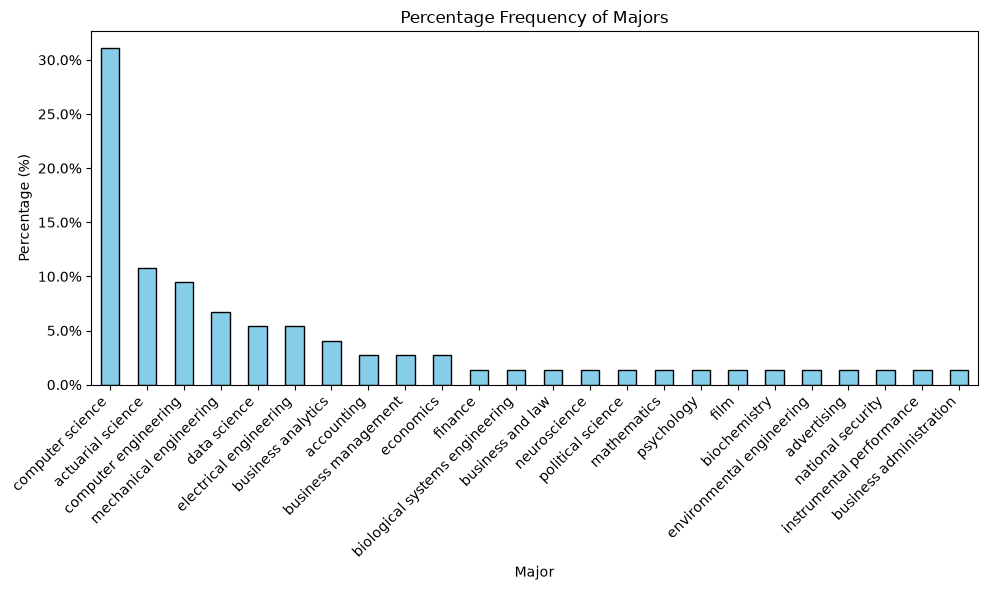

In [327]:
# Count frequencies and plot
ax = (df['major'].value_counts(normalize=True) * 100).plot(
    kind='bar', 
    figsize=(10, 6), 
    color='skyblue', 
    edgecolor='black'
)

plt.title('Percentage Frequency of Majors')
plt.xlabel('Major')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45, ha='right')  # Rotates labels so they don't overlap

# Format y-axis tick labels with a '%' sign
ax.yaxis.set_major_formatter(mtick.PercentFormatter())

plt.tight_layout()
plt.show()

### Plotting Study Genres

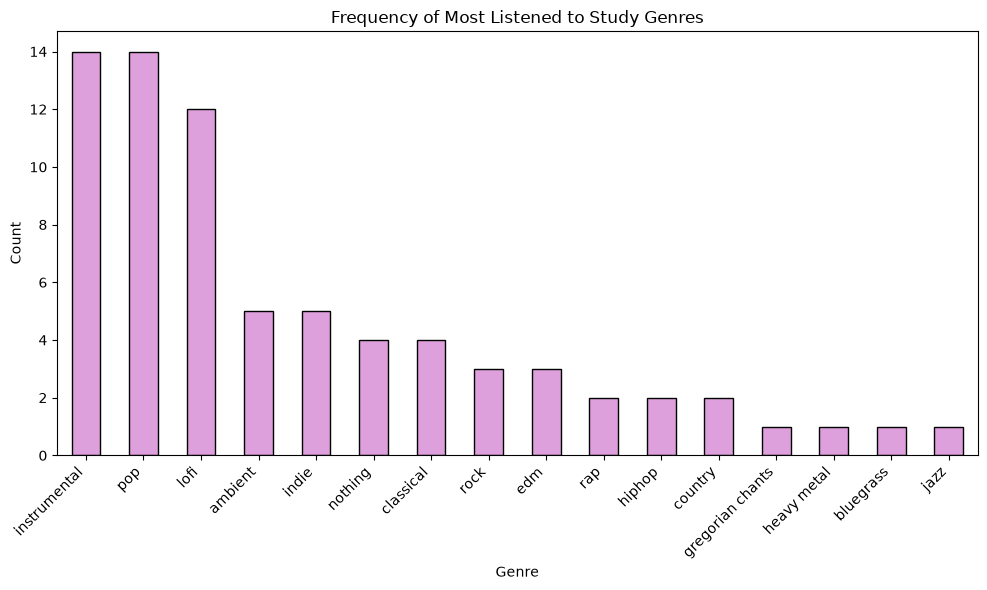

In [328]:
# Count frequencies and plot
df['study_music_genre'].value_counts().plot(kind='bar', figsize=(10, 6), color='plum', edgecolor='black')

plt.title('Frequency of Most Listened to Study Genres')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')  # Rotates labels so they don't overlap
plt.tight_layout()
plt.show()

### Plotting Leisure Genres

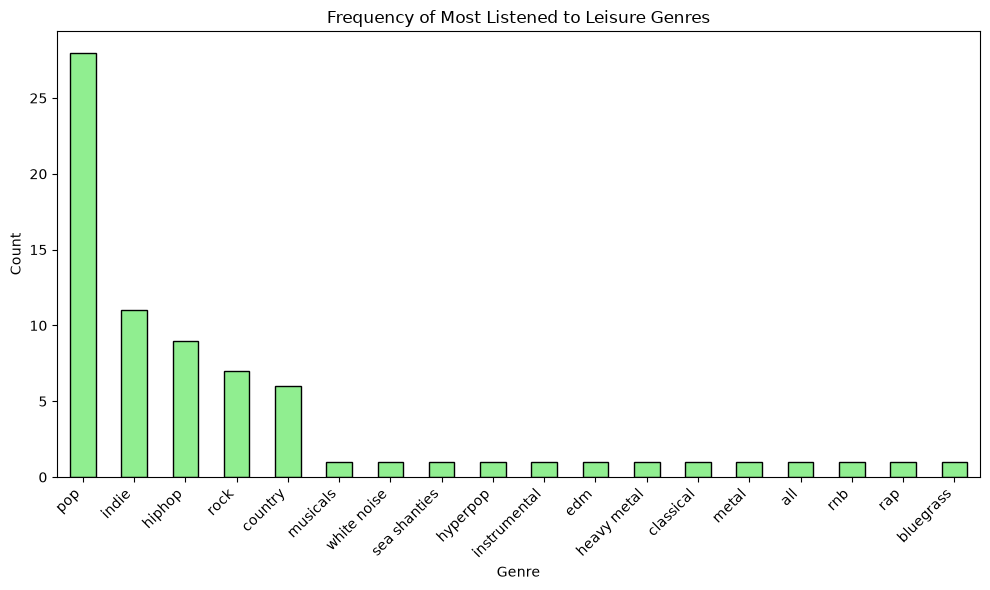

In [329]:
# Count frequencies and plot 
df['leisure_music_genre'].value_counts().plot(kind='bar', figsize=(10, 6), color='lightgreen', edgecolor='black')

plt.title('Frequency of Most Listened to Leisure Genres')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')  # Rotates labels so they don't overlap
plt.tight_layout()
plt.show()

### Plotting Study Habits

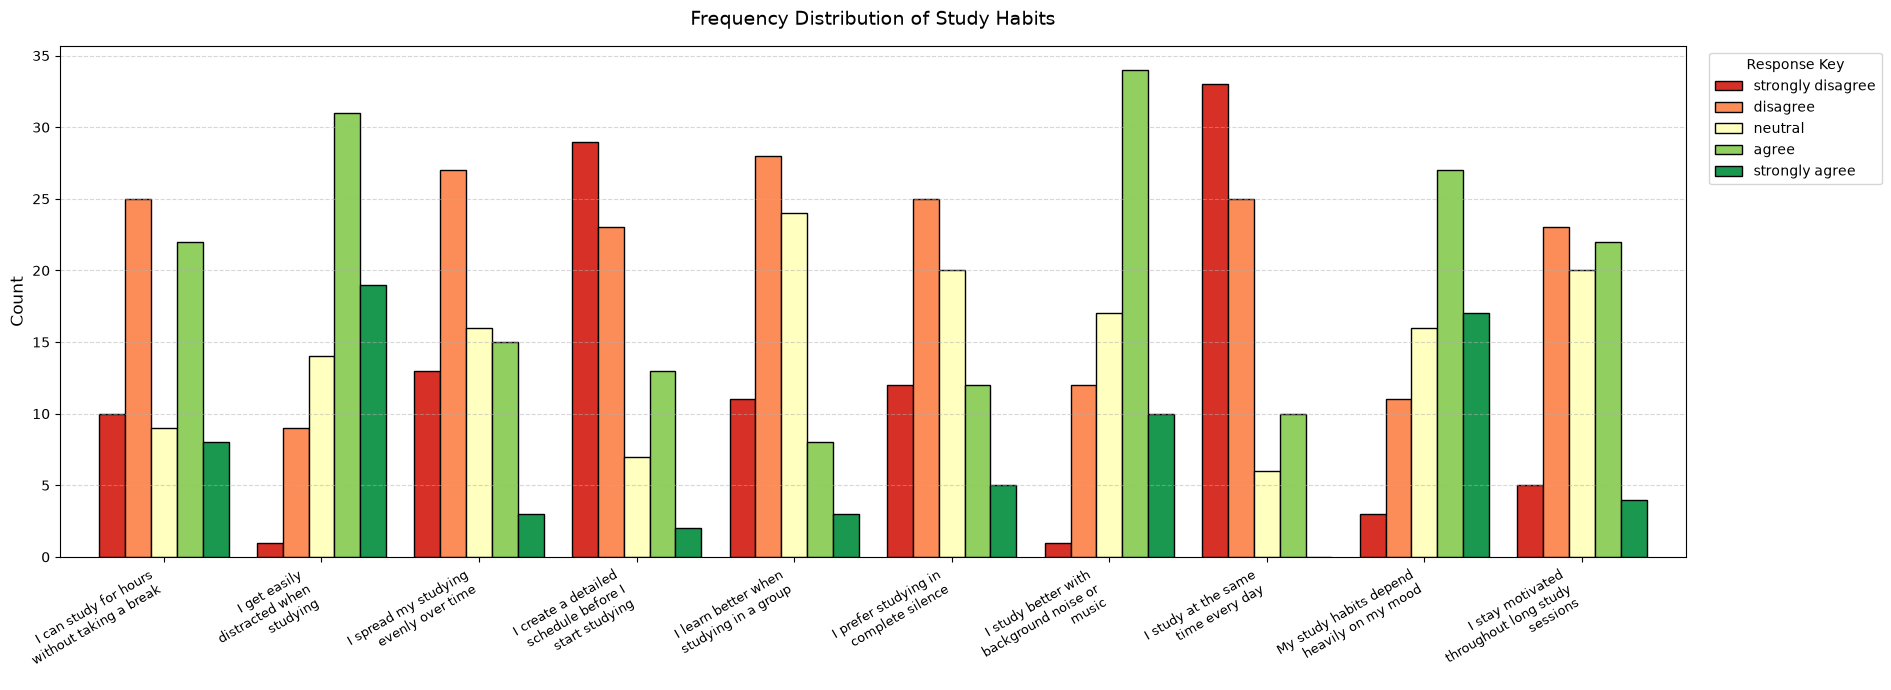

In [330]:
import textwrap

feature_mapping = {
    'study_long_without_breaks': "I can study for hours without taking a break",
    'study_easily_distracted': "I get easily distracted when studying",
    'study_spaced_evenly': "I spread my studying evenly over time",
    'study_uses_detailed_schedule': "I create a detailed schedule before I start studying",
    'study_prefers_group': "I learn better when studying in a group",
    'study_prefers_silence': "I prefer studying in complete silence",
    'study_prefers_background_audio': "I study better with background noise or music",
    'study_consistent_time': "I study at the same time every day",
    'study_mood_dependent': "My study habits depend heavily on my mood",
    'study_sustained_motivation': "I stay motivated throughout long study sessions"
}

value_mapping = {
    -2: 'strongly disagree',
    -1: 'disagree',
    0: 'neutral',
    1: 'agree',
    2: 'strongly agree'
}

# 1. Calculate frequencies for each feature and enforce the -2 to 2 column order
cols = list(feature_mapping.keys())
counts_df = df[cols].apply(lambda col: col.value_counts()).T.fillna(0)
counts_df = counts_df.reindex(columns=[-2, -1, 0, 1, 2], fill_value=0)

# 2. Wrap long x-axis labels so they fit underneath each bar group
wrapped_labels = [textwrap.fill(feature_mapping[col], width=22) for col in cols]
counts_df.index = wrapped_labels

# 3. Map columns to legend labels and assign 5 diverging colors
counts_df = counts_df.rename(columns=value_mapping)
colors = ['#d73027', '#fc8d59', '#ffffbf', '#91cf60', '#1a9850']  # Dark red -> Orange -> Yellow -> Light green -> Dark green

ax = counts_df.plot(
    kind='bar',
    color=colors,
    edgecolor='black',
    width=0.82,
    figsize=(19, 7)
)

# 4. Formatting & Legend
plt.title('Frequency Distribution of Study Habits', fontsize=14, pad=15)
plt.ylabel('Count', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.legend(title='Response Key', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Plotting Listening Habits

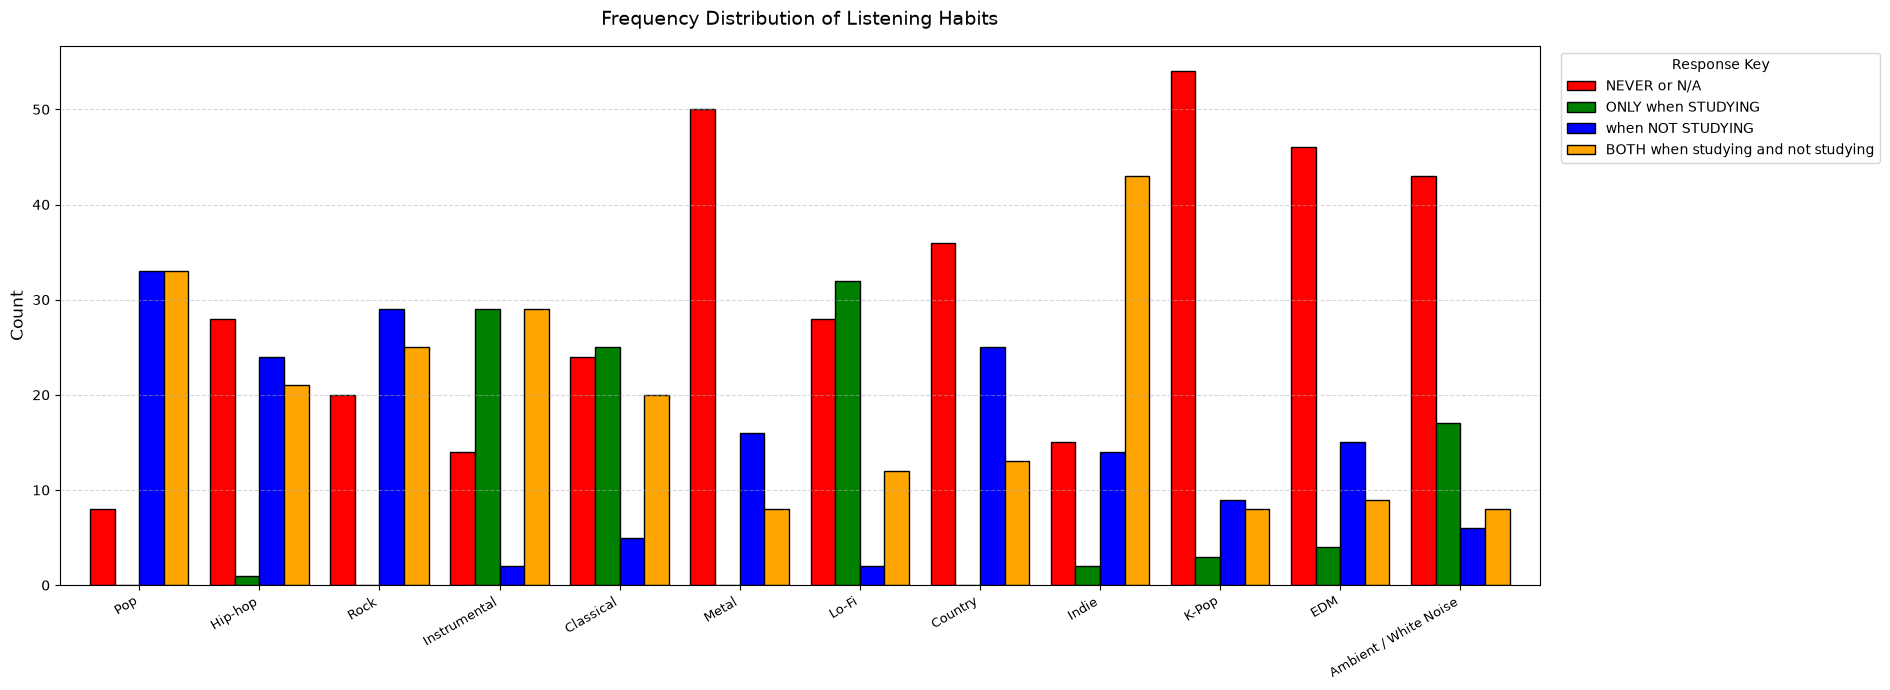

In [331]:
feature_mapping = {
    'pop': 'Pop',
    'hiphop': 'Hip-hop',
    'rock': 'Rock',
    'instrumental': 'Instrumental',
    'classical': 'Classical',
    'metal': 'Metal',
    'lofi': 'Lo-Fi',
    'country': 'Country',
    'indie': 'Indie',
    'kpop': 'K-Pop',
    'edm': 'EDM',
    'ambient': 'Ambient / White Noise'
}

value_mapping = {
    0: 'NEVER or N/A',
    1: 'ONLY when STUDYING',
    2: 'when NOT STUDYING',
    3: 'BOTH when studying and not studying'
}

# 1. Calculate frequencies for each feature and enforce the 0 to 3 column order
cols = list(feature_mapping.keys())
counts_df = df[cols].apply(lambda col: col.value_counts()).T.fillna(0)
counts_df = counts_df.reindex(columns=[0, 1, 2, 3], fill_value=0)

# 2. Wrap long x-axis labels so they fit underneath each bar group
wrapped_labels = [textwrap.fill(feature_mapping[col], width=22) for col in cols]
counts_df.index = wrapped_labels

# 3. Map columns to legend labels and assign 5 diverging colors
counts_df = counts_df.rename(columns=value_mapping)
colors = ['red', 'green', 'blue', 'orange']

ax = counts_df.plot(
    kind='bar',
    color=colors,
    edgecolor='black',
    width=0.82,
    figsize=(19, 7)
)

# 4. Formatting & Legend
plt.title('Frequency Distribution of Listening Habits', fontsize=14, pad=15)
plt.ylabel('Count', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.legend(title='Response Key', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()



### Plotting Likert Scale

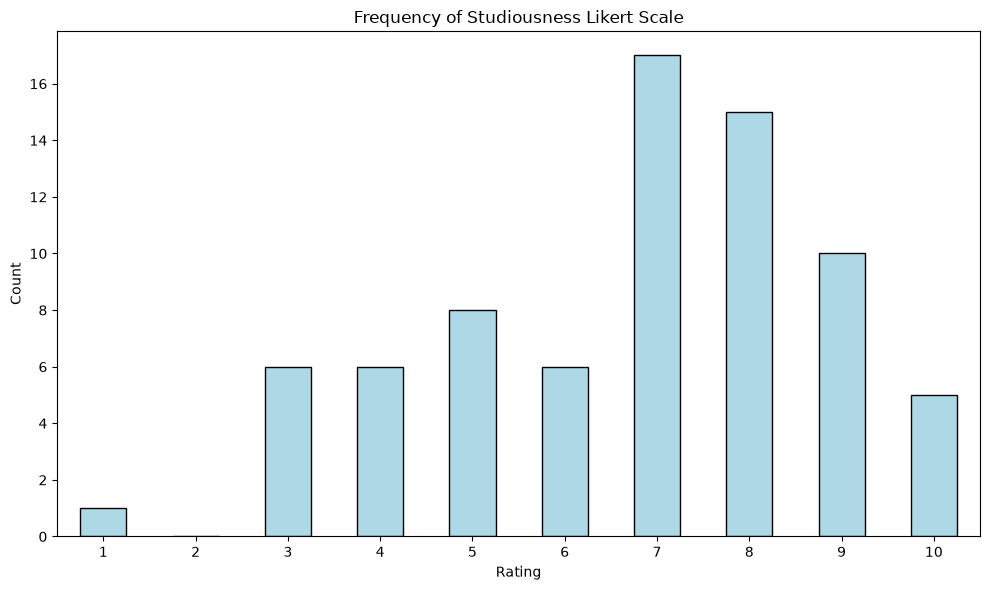

In [332]:
# Count frequencies, sort by value (1 to 10), and plot
df['study_index'].value_counts().reindex(range(1, 11), fill_value=0).plot(
    kind='bar', 
    figsize=(10, 6), 
    color='lightblue', 
    edgecolor='black'
)

plt.title('Frequency of Studiousness Likert Scale')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()